In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

from scipy.cluster.hierarchy import dendrogram, linkage

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df= pd.read_csv("customers.csv")
df.head()

,CustomerID,Genre,Age,Annual_Income,Spending_Score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16 entries, 0 to 15
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   CustomerID      16 non-null     int64 
 1   Genre           16 non-null     object
 2   Age             16 non-null     int64 
 3   Annual_Income   16 non-null     int64 
 4   Spending_Score  16 non-null     int64 
dtypes: int64(4), object(1)
memory usage: 772.0+ bytes


In [5]:
df.describe()

,CustomerID,Age,Annual_Income,Spending_Score
count,16.000000,16.000000,16.000000,16.000000
mean,8.500000,33.187500,33.250000,48.062500
std,4.760952,15.938292,21.699462,31.833879
min,1.000000,19.000000,15.000000,3.000000
25%,4.750000,22.000000,16.750000,14.750000
50%,8.500000,27.000000,18.500000,45.000000
75%,12.250000,35.500000,60.000000,77.000000
max,16.000000,67.000000,61.000000,94.000000


In [6]:
df.isnull().sum()

CustomerID        0
Genre             0
Age               0
Annual_Income     0
Spending_Score    0
dtype: int64

In [8]:
df.shape

(16, 5)

In [19]:
X = df[['Annual_Income', 'Spending_Score']]
print(X.head())

   Annual_Income  Spending_Score
0             15              39
1             15              81
2             16               6
3             16              77
4             17              40


In [20]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled[:5])

[[-0.86861686 -0.29401726]
 [-0.86861686  1.06860066]
 [-0.82102142 -1.36464562]
 [-0.82102142  0.93882752]
 [-0.77342598 -0.26157398]]


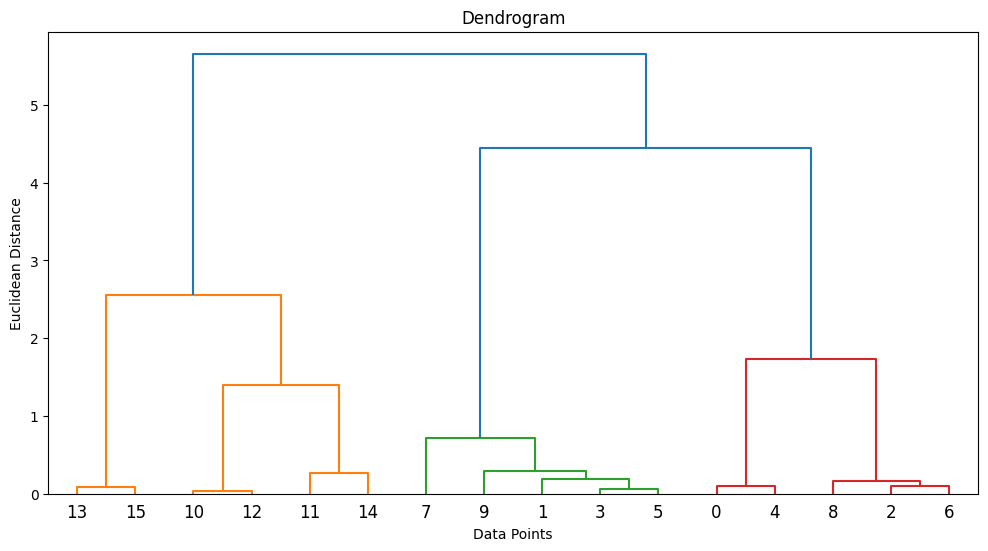

In [21]:
Z = linkage(X_scaled, method='ward')

plt.figure(figsize=(12, 6))

dendrogram(Z)

plt.title("Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")
plt.show()

In [22]:
model = AgglomerativeClustering(
    n_clusters=5,
    linkage='ward'
)

df['Cluster'] = model.fit_predict(X_scaled)

print(df.head(10))

   CustomerID   Genre  Age  Annual_Income  Spending_Score  Cluster
0           1    Male   19             15              39        4
1           2    Male   21             15              81        2
2           3  Female   20             16               6        1
3           4  Female   23             16              77        2
4           5  Female   31             17              40        4
5           6  Female   22             17              76        2
6           7  Female   35             18               6        1
7           8  Female   23             18              94        2
8           9    Male   64             19               3        1
9          10  Female   30             19              72        2


In [23]:
print(df['Cluster'].value_counts())

Cluster
2    5
0    4
1    3
4    2
3    2
Name: count, dtype: int64


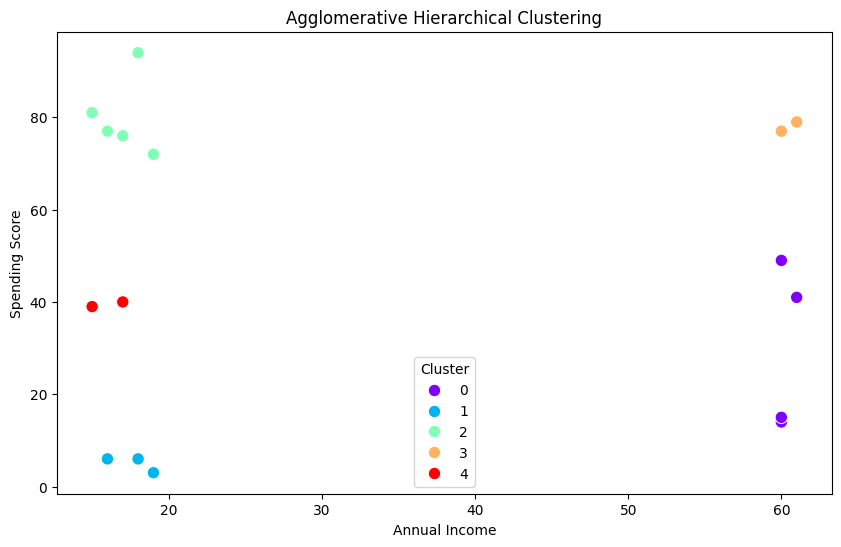

In [25]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=df['Annual_Income'],
    y=df['Spending_Score'],
    hue=df['Cluster'],
    palette='rainbow',
    s=80
)

plt.title("Agglomerative Hierarchical Clustering")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")

plt.show()

In [27]:
print("Cluster-wise Average:")

print(
    df.groupby('Cluster')[
        ['Annual_Income', 'Spending_Score']
    ].mean()
)

Cluster-wise Average:
         Annual_Income  Spending_Score
Cluster                               
0            60.250000           29.75
1            17.666667            5.00
2            17.000000           80.00
3            60.500000           78.00
4            16.000000           39.50
